# PIPE_Mask Dataset Exploration

Exploration of inpainting masks from the Paint-by-Inpaint (PIPE) dataset.

## Dataset Overview & Schema

- **Source Used for Analysis:** Hugging Face [`paint-by-inpaint/PIPE_Masks`](https://huggingface.co/datasets/paint-by-inpaint/PIPE_Masks)
- **Where to Get Full Dataset Later:** Hugging Face repository [https://huggingface.co/datasets/paint-by-inpaint/PIPE_Masks](https://huggingface.co/datasets/paint-by-inpaint/PIPE_Masks)
- **Full Dataset Size:** ~4 GB (888,230 binary inpainting masks in Parquet format: 25.9% COCO, 74.1% Open Images)
- **Use in Project:** Provides ready-to-use realistic object masks for inpainting evaluation without needing manual mask generation

### Dataset Schema
| Column | Type | Description |
| :--- | :--- | :--- |
| `mask` | `PIL.JpegImageFile` | Grayscale binary inpainting mask (mode `L`, $512 \times 512$). |
| `target_img_dataset` | `str` | Name of parent dataset: `'COCO'` (~25.9%) or `'OpenImages'` (~74.1%). |
| `img_id` | `str` | Image identifier in the parent dataset. |
| `ann_id` | `str` | Annotation identifier in the parent dataset. |


### 1. Load PIPE_Mask dataset


In [1]:
from datasets import load_dataset

# Load the PIPE_Masks dataset containing ~888k inpainting masks
ds = load_dataset("paint-by-inpaint/PIPE_Masks", split="train")


### 2. Inspect a sample record


In [17]:
# Inspect first mask record and metadata
ds[0]


{'mask': <PIL.JpegImagePlugin.JpegImageFile image mode=L size=512x512>,
 'target_img_dataset': 'COCO',
 'img_id': '339734',
 'ann_id': '200890'}

### 3. Display sample inpainting mask


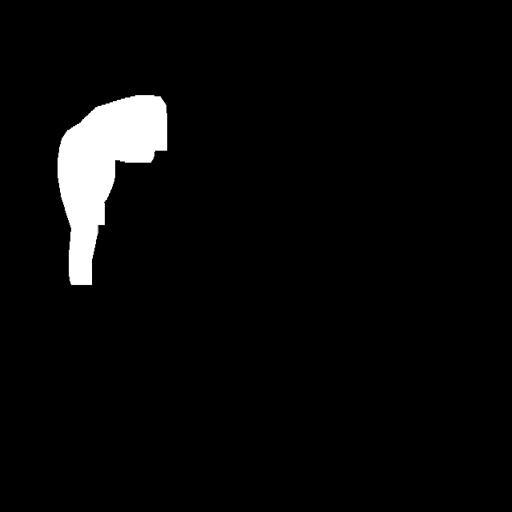

In [18]:
# Display sample inpainting mask
ds[0]["mask"]


### 4. Count masks per source dataset


In [7]:
from collections import Counter

# Count distribution of masks across source datasets
col_ds = ds.select_columns(["target_img_dataset"])
result_dict = dict(Counter(col_ds["target_img_dataset"]))


### 5. Display raw counts


In [8]:
# Print raw counts per dataset
print(result_dict)


{'COCO': 230076, 'OpenImages': 658154}


### 6. Calculate percentage distribution


In [16]:
import pandas as pd

# Compute percentage distribution of masks (COCO vs OpenImages)
result_df = pd.DataFrame(result_dict, index=[0]).T
result_df[0] = (result_df[0] / result_df[0].sum()) * 100
result_df


,0
COCO,25.90275
OpenImages,74.09725
